# Using my Modelling Code to Make Paper Figures

In [1]:
import os  # noqa: I001
import numpy as np
import numpy.random as rd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from ode_model import ode_lotka

filepath = os.path.abspath("")
datadir = f'{filepath}/data/'
figdir = f'{filepath}/figures/'
np.random.seed(42)

In [2]:
def reindex_data(ode_index, y, t_end=100):
    """A function that will reindex the results of the ODE solver to exactly fit the timeframe 0-t_end, so that averages can be taken between simulations.
    
    Parameters:
    ------------
    ode_intex: np.array
        the timesteps the ode has actually solved for (often not 0-t_end with steps of 1)
    y: np.array
        the values the ode has solved for
    t_end: integer, default=100
        the ending timestep to reindex for"""
    new_index = np.arange(0,t_end+1)
    df = pd.DataFrame(np.array(y).T, index=ode_index)
    return df.reindex(index=new_index, method='nearest').to_numpy().T

## Show Conjugation in a Community without Colonisation Resistance

In [3]:
# --- PARAMETERS FOR NO CR ---

# Number of species to use
n_species = 1                              # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 0                           # community connectivty (probability of interactions)
sigma = 1e-5                               # interspecies interaction strength standard deviation
P_m = 0                                    # proportion of species reactions that are positive
self_inhibition = 0.1                      # intra-specific interaction strength

# Parameters for the model
conjugation_rate = 5e-4                    # average plasmid conjugation rate

# Parameters at the start of the model
t_start = 0                                # starting timestep
t_end = 100                               # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                      # starting population size

### Modelling Different Selections

#### Modelling a simple 1-species community that provides no colonisation resistance and no antibiotic
This is showing that the donor and recipient are able to grow to carrying capacity and transconjugants are able to form.

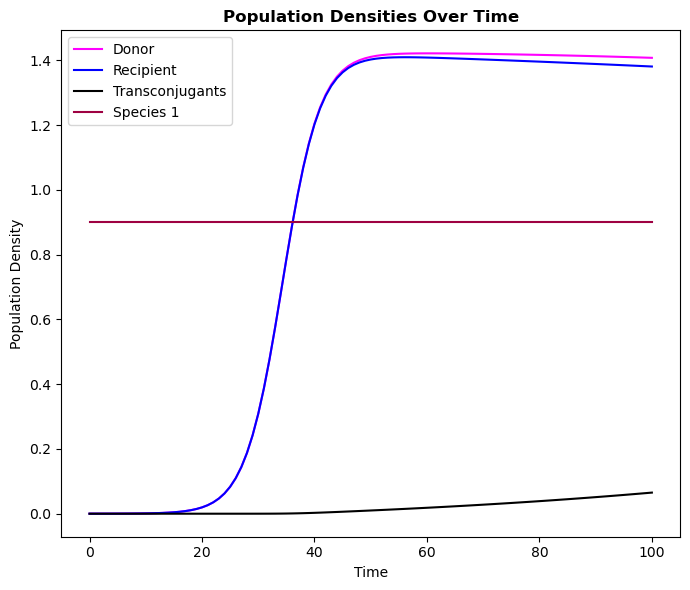

In [4]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
susceptibility = [0.05, 0.05, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                             # magnitude of perturbation, between 0 and 1

# --- MODEL FOR NO CR ---
no_cr_trans = []
repeats = 100
for r in range(repeats):
    no_cr = ode_lotka(n_species)
    no_cr.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    no_cr.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    no_cr_trans.append(reindex_data(no_cr.results.t, no_cr.results.y, t_end=t_end))
no_cr_trans = np.array(no_cr_trans)
np.save(f'{datadir}/exp_no_cr_trans', no_cr_trans)
no_cr.plot_results(no_cr.results.t, no_cr.results.y.T, 'Population Densities Over Time')

#### Modelling a simple 1-species community that provides no colonisation resistance and with an antibiotic that directly selects against the donor
This is showing that the donor is not as able to grow well.

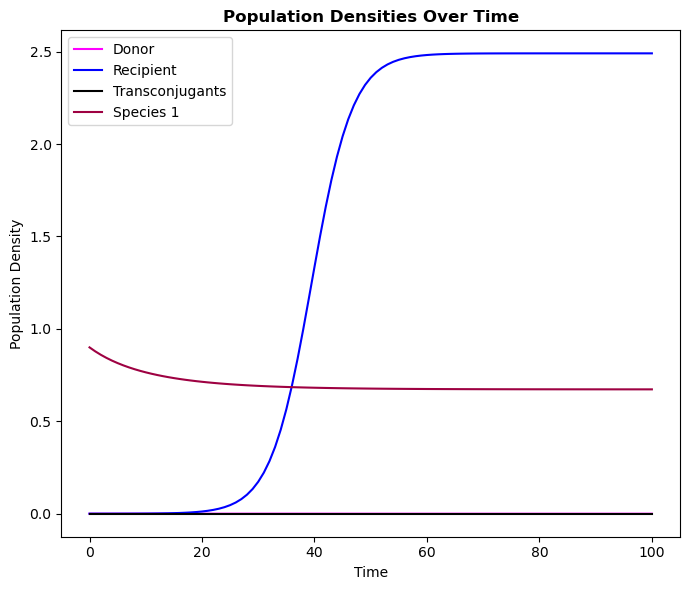

In [5]:
# --- PARAMETERS FOR DIRECT SELECTION AGAINST DONOR ---
susceptibility = [0.5, 0.05, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION AGAINST DONOR ---
direct_selection_donor_trans = []
repeats = 100
for r in range(repeats):
    direct_selection_donor = ode_lotka(n_species)
    direct_selection_donor.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    direct_selection_donor.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    direct_selection_donor_trans.append(direct_selection_donor.results.y[:, -1])
direct_selection_donor.plot_results(direct_selection_donor.results.t, direct_selection_donor.results.y.T, 'Population Densities Over Time')

#### Modelling a simple 1-species community that provides no colonisation resistance and with an antibiotic that directly selects against the recipient
This is showing that the recipient is not as able to grow well and therefore there are no bacteria that can receive the plasmid and form transconjugants

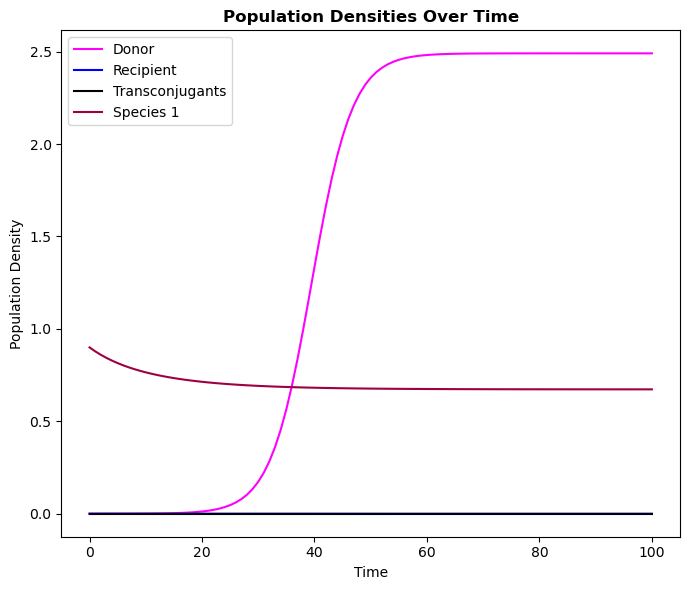

In [6]:
# --- PARAMETERS FOR DIRECT SELECTION AGAINST RECIPIENT ---
susceptibility = [0.05, 0.5, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION ---
direct_selection_recip_trans = []
repeats = 100
for r in range(repeats):
    direct_selection_recip = ode_lotka(n_species)
    direct_selection_recip.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    direct_selection_recip.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    direct_selection_recip_trans.append(direct_selection_recip.results.y[:, -1])
direct_selection_recip.plot_results(direct_selection_recip.results.t, direct_selection_recip.results.y.T, 'Population Densities Over Time')

### Modelling a simple 1-species community that provides no colonisation resistance cycling through donor and recipient susceptibilities

In [7]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
donor_sus = np.linspace(0, 1, 21)          # donor susceptibility
recip_sus = np.linspace(0, 1, 21)          # recipient susceptibility
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION ---
repeats = 5
compare_selections_trans = np.zeros([len(recip_sus), len(donor_sus), repeats])
for r in range(repeats):
    print(f'\nStarting repeat {r+1}')
    compare_selections = ode_lotka(n_species)
    compare_selections.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'Iterating through donor susceptibility {ds+1}')
        for rs in range(len(recip_sus)):
            susceptibility = [donor_sus[ds], recip_sus[rs], np.min([donor_sus[ds], recip_sus[rs]]), 0.05]
            compare_selections.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
            compare_selections_trans[rs][ds][r] = compare_selections.results.y[2, -1]
np.save(f'{datadir}/exp_no_cr_sus', compare_selections_trans)


Starting repeat 1
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterating through donor susceptibility 3
Iterating through donor susceptibility 4
Iterating through donor susceptibility 5
Iterating through donor susceptibility 6
Iterating through donor susceptibility 7
Iterating through donor susceptibility 8
Iterating through donor susceptibility 9
Iterating through donor susceptibility 10
Iterating through donor susceptibility 11
Iterating through donor susceptibility 12
Iterating through donor susceptibility 13
Iterating through donor susceptibility 14
Iterating through donor susceptibility 15
Iterating through donor susceptibility 16
Iterating through donor susceptibility 17
Iterating through donor susceptibility 18
Iterating through donor susceptibility 19
Iterating through donor susceptibility 20
Iterating through donor susceptibility 21

Starting repeat 2
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterati

### Comparing these simulations

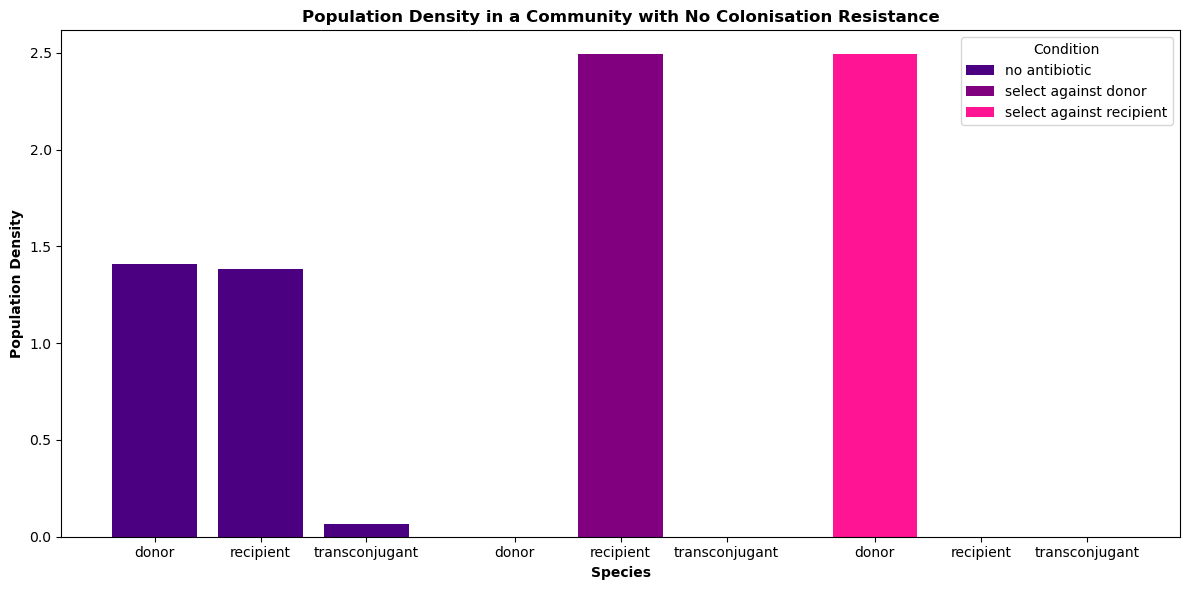

In [8]:
# --- PLOT SPECIES DENSITIES WHEN HAVING DIRECT SELECTION AGAINST DONOR ---
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(x=[0.25,0.5,0.75], height=no_cr_trans[:,0:3,-1].mean(axis=0), width=0.2, label='no antibiotic', color='indigo')
plt.bar(x=[1.1,1.35,1.6], height=np.array(direct_selection_donor_trans)[:,0:3].mean(axis=0), width=0.2, label='select against donor', color='purple')
plt.bar(x=[1.95,2.2,2.45], height=np.array(direct_selection_recip_trans)[:,0:3].mean(axis=0), width=0.2, label='select against recipient', color='deeppink')
plt.title('Population Density in a Community with No Colonisation Resistance', fontweight='bold')
plt.xlabel('Species', fontweight='bold')
plt.xticks([0.25,0.5,0.75, 1.1,1.35,1.6, 1.95,2.2,2.45], labels=['donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant'])
plt.ylabel('Population Density', fontweight='bold')
plt.legend(title='Condition')
plt.tight_layout()
plt.show()

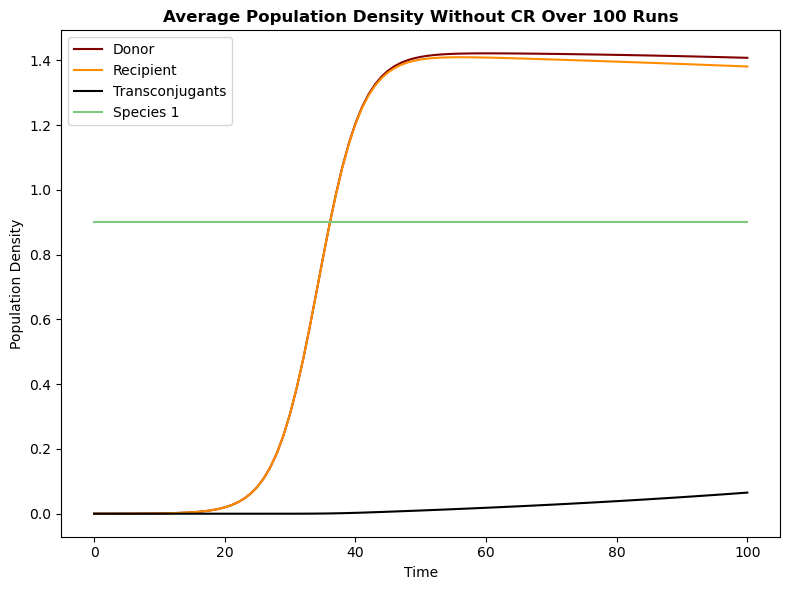

In [9]:
no_cr.plot_results(np.arange(0,101), no_cr_trans.mean(axis=0).T,
                   title='Average Population Density Without CR Over 100 Runs',
                   drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                   figsize=(8,6), save_fig=True, filename=f'{figdir}/exp_nocr')

## Show Conjugation in a Highly Resistant Community

In [10]:
# --- PARAMETERS FOR CR ---

# Number of species to use
n_species = 1                              # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                           # community connectivty (probability of interactions)
sigma = 0.6                                # interspecies interaction strength standard deviation
P_m = 0                                    # proportion of species reactions that are positive
self_inhibition = 0.1                      # intra-specific interaction strength

# Parameters for the model
conjugation_rate = 5e-4                    # average plasmid conjugation rate

# Parameters at the start of the model
t_start = 0                                # starting timestep
t_end = 100                               # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                      # starting population size

### Modelling Different Selections

#### Modelling a simple 1-species community that provides colonisation resistance and no antibiotic
This is showing that the donor and recipient are able to grow to carrying capacity and transconjugants are able to form.

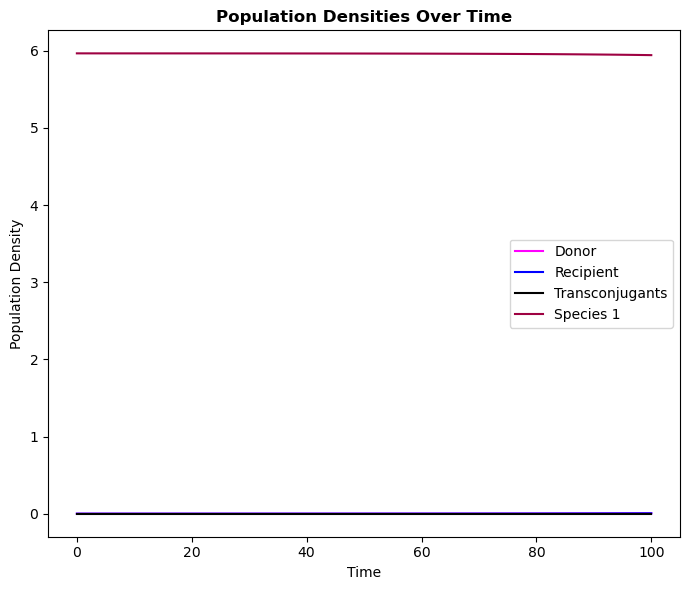

In [11]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
susceptibility = [0.05, 0.05, 0.05, 0.05]      # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                             # magnitude of perturbation, between 0 and 1

# --- MODEL FOR NO CR ---
cr_trans = []
repeats = 100
for r in range(repeats):
    cr = ode_lotka(n_species)
    cr.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    cr.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    cr_trans.append(reindex_data(cr.results.t, cr.results.y, t_end=t_end))
cr_trans = np.array(cr_trans)
np.save(f'{datadir}/exp_cr_trans', cr_trans)
cr.plot_results(cr.results.t, cr.results.y.T, 'Population Densities Over Time')

#### Remove CR with Antibiotics

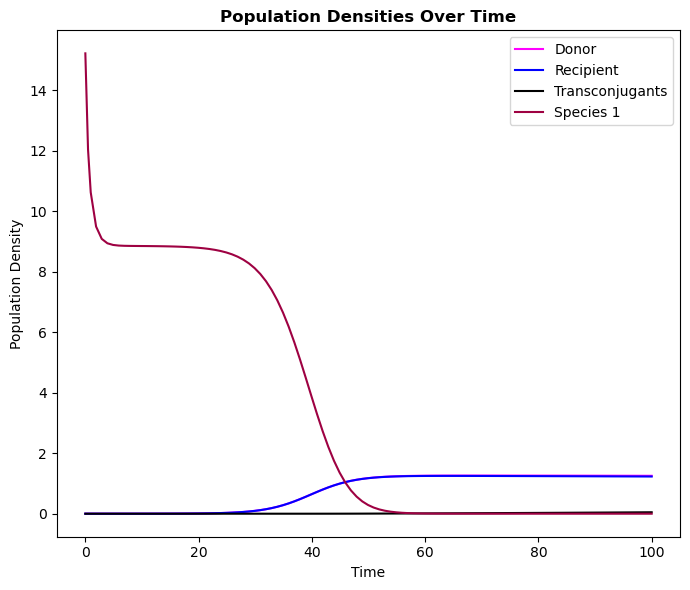

In [12]:
# --- PARAMETERS FOR REMOVING CR WITH ANTIBIOTICS ---
susceptibility = [0.05, 0.05, 0.05, 1]        # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR REMOVE CR WITH ANTIBIOTICS ---
cr_perturb_trans = []
repeats = 100
for r in range(repeats):
    cr_perturb = ode_lotka(n_species)
    cr_perturb.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    cr_perturb.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
    cr_perturb_trans.append(reindex_data(cr_perturb.results.t, cr_perturb.results.y, t_end=t_end))
cr_perturb_trans = np.array(cr_perturb_trans)
np.save(f'{datadir}/exp_cr_perturb', cr_perturb_trans)
cr_perturb.plot_results(cr_perturb.results.t, cr_perturb.results.y.T, 'Population Densities Over Time')

### Modelling a simple 1-species community that provides colonisation resistance cycling through donor and recipient susceptibilities

In [13]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
donor_sus = np.linspace(0, 1, 21)          # donor susceptibility
recip_sus = np.linspace(0, 1, 21)          # recipient susceptibility
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION WITH A NOT VERY SUSCEPTIBLE COMMUNITY ---
repeats = 5
cr_compare_selections_trans = np.zeros([len(recip_sus), len(donor_sus), repeats])
for r in range(repeats):
    print(f'\nStarting repeat {r+1}')
    cr_compare_selections = ode_lotka(n_species)
    cr_compare_selections.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'Iterating through donor susceptibility {ds+1}')
        for rs in range(len(recip_sus)):
            susceptibility = [donor_sus[ds], recip_sus[rs], np.min([donor_sus[ds], recip_sus[rs]]), 0.05]
            cr_compare_selections.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
            cr_compare_selections_trans[rs][ds][r] = cr_compare_selections.results.y[2, -1]
np.save(f'{datadir}/exp_cr_sus', cr_compare_selections_trans)


Starting repeat 1
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterating through donor susceptibility 3
Iterating through donor susceptibility 4
Iterating through donor susceptibility 5
Iterating through donor susceptibility 6
Iterating through donor susceptibility 7
Iterating through donor susceptibility 8
Iterating through donor susceptibility 9
Iterating through donor susceptibility 10
Iterating through donor susceptibility 11
Iterating through donor susceptibility 12
Iterating through donor susceptibility 13
Iterating through donor susceptibility 14
Iterating through donor susceptibility 15
Iterating through donor susceptibility 16
Iterating through donor susceptibility 17
Iterating through donor susceptibility 18
Iterating through donor susceptibility 19
Iterating through donor susceptibility 20
Iterating through donor susceptibility 21

Starting repeat 2
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterati

In [14]:
# --- SUSCEPTIBILITY ADJUSTMENTS FOR MODEL ---
donor_sus = np.linspace(0, 1, 21)          # donor susceptibility
recip_sus = np.linspace(0, 1, 21)          # recipient susceptibility
drug_level = 0.7                           # magnitude of perturbation, between 0 and 1

# --- MODEL FOR DIRECT SELECTION WITH A VERY SUSCEPTIBLE COMMUNITY ---
repeats = 5
cr_recover_trans = np.zeros([len(recip_sus), len(donor_sus), repeats])
for r in range(repeats):
    print(f'\nStarting repeat {r+1}')
    cr_recover = ode_lotka(n_species)
    cr_recover.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'Iterating through donor susceptibility {ds+1}')
        for rs in range(len(recip_sus)):
            susceptibility = [donor_sus[ds], recip_sus[rs], np.min([donor_sus[ds], recip_sus[rs]]), 1]
            cr_recover.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
            cr_recover_trans[rs][ds][r] = cr_recover.results.y[2, -1]
np.save(f'{datadir}/exp_cr_perturb_sus', cr_recover_trans)


Starting repeat 1
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterating through donor susceptibility 3
Iterating through donor susceptibility 4
Iterating through donor susceptibility 5
Iterating through donor susceptibility 6
Iterating through donor susceptibility 7
Iterating through donor susceptibility 8
Iterating through donor susceptibility 9
Iterating through donor susceptibility 10
Iterating through donor susceptibility 11
Iterating through donor susceptibility 12
Iterating through donor susceptibility 13
Iterating through donor susceptibility 14
Iterating through donor susceptibility 15
Iterating through donor susceptibility 16
Iterating through donor susceptibility 17
Iterating through donor susceptibility 18
Iterating through donor susceptibility 19
Iterating through donor susceptibility 20
Iterating through donor susceptibility 21

Starting repeat 2
Iterating through donor susceptibility 1
Iterating through donor susceptibility 2
Iterati

### Comparing these simulations

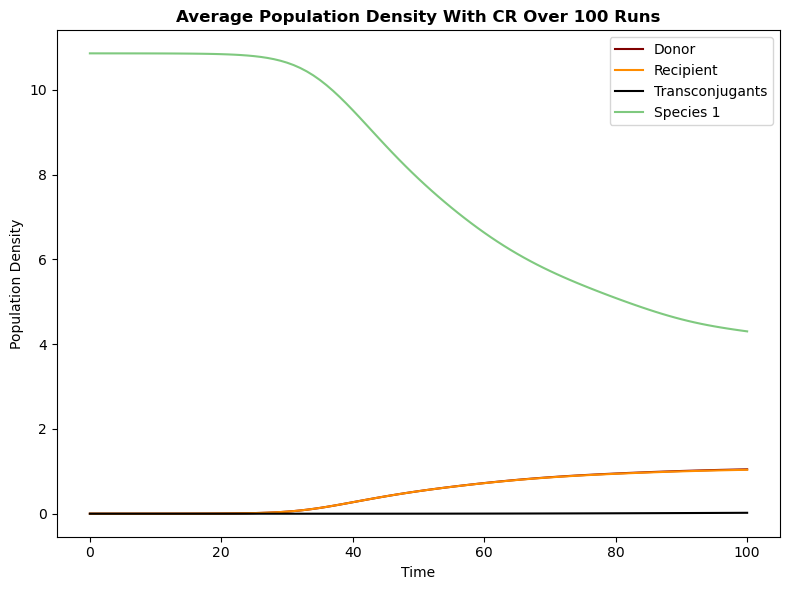

In [15]:
cr.plot_results(np.arange(0,101), cr_trans.mean(axis=0).T,
                title='Average Population Density With CR Over 100 Runs',
                drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                figsize=(8,6), save_fig=True, filename=f'{figdir}/exp_cr')

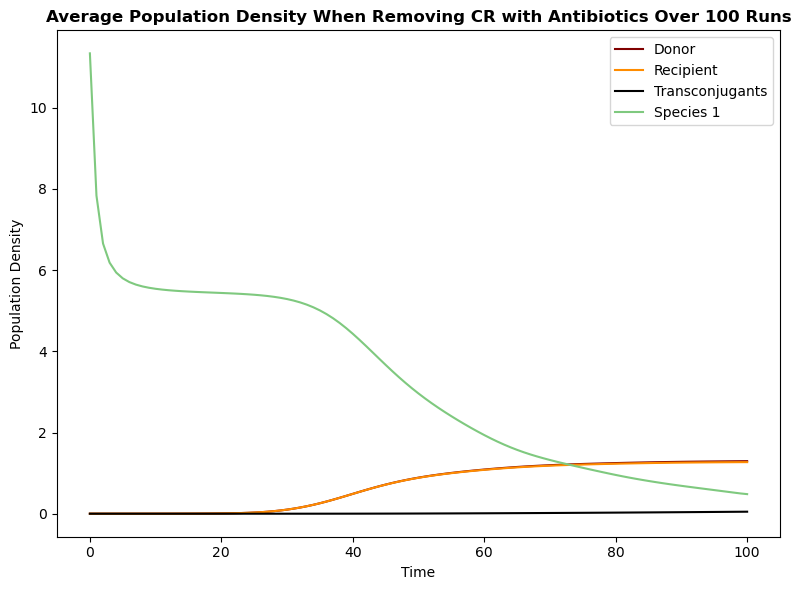

In [16]:
cr_perturb.plot_results(np.arange(0,101), cr_perturb_trans.mean(axis=0).T,
                        title='Average Population Density When Removing CR with Antibiotics Over 100 Runs',
                        drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                        figsize=(8,6), save_fig=True, filename=f'{figdir}/exp_cr_perturb')

## Compare Community With and Without Colonisation Resistance

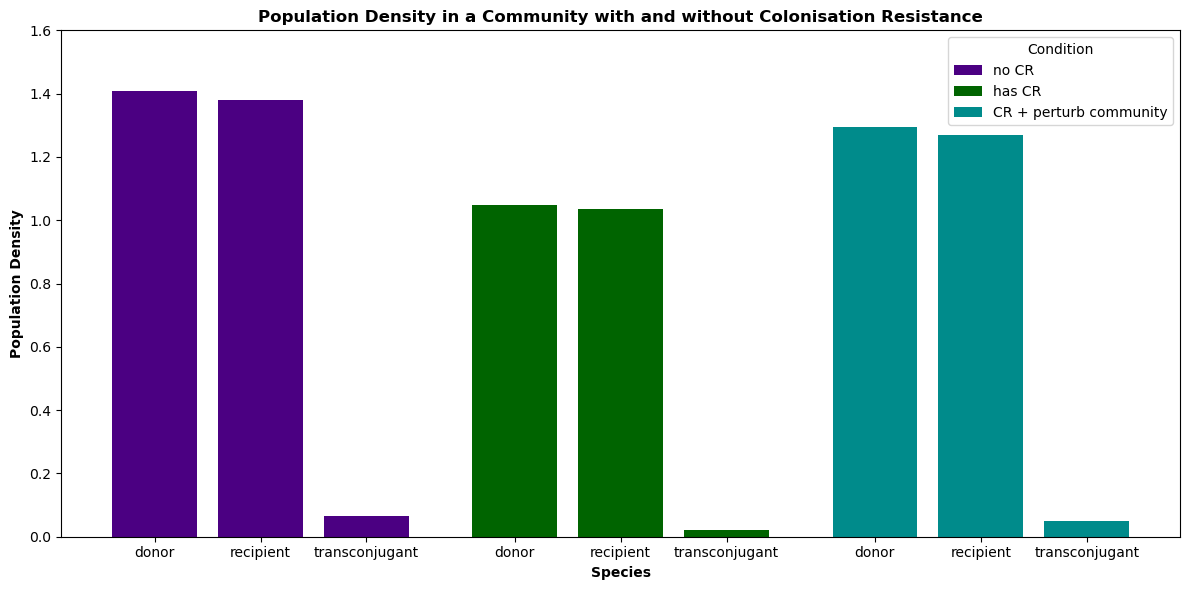

In [17]:
# --- PLOT SPECIES DENSITIES WHEN HAVING DIRECT SELECTION AGAINST DONOR ---
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(x=[0.25,0.5,0.75], height=no_cr_trans[:,0:3,-1].mean(axis=0), width=0.2, label='no CR', color='indigo')
plt.bar(x=[1.1,1.35,1.6], height=cr_trans[:,0:3,-1].mean(axis=0), width=0.2, label='has CR', color='darkgreen')
plt.bar(x=[1.95,2.2,2.45], height=cr_perturb_trans[:,0:3,-1].mean(axis=0), width=0.2, label='CR + perturb community', color='darkcyan')
plt.title('Population Density in a Community with and without Colonisation Resistance', fontweight='bold')
plt.xlabel('Species', fontweight='bold')
plt.xticks([0.25,0.5,0.75, 1.1,1.35,1.6, 1.95,2.2,2.45], labels=['donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant', 'donor', 'recipient', 'transconjugant'])
plt.ylabel('Population Density', fontweight='bold')
plt.ylim(0,1.6)
plt.legend(title='Condition')
plt.tight_layout()
plt.savefig(f'{figdir}/exp_changeCR_compare.png', dpi=500)
plt.show()

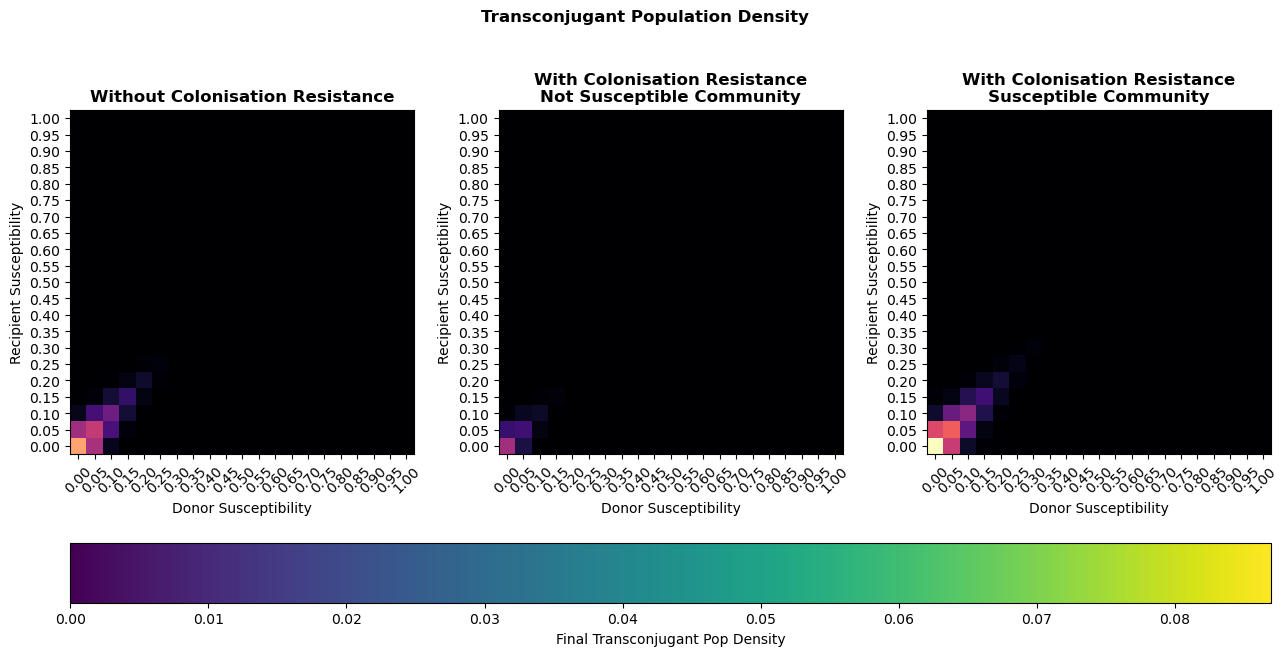

In [18]:
# --- COMPARING ALL OF THE DONOR AND RECIPIENT SUSCEPTIBILITIES ---
fig, ax = plt.subplots(1,3, figsize=(13,6.5))
normalizer = Normalize(np.min([compare_selections_trans.mean(axis=2),cr_compare_selections_trans.mean(axis=2),cr_recover_trans.mean(axis=2)]), np.max([compare_selections_trans.mean(axis=2),cr_compare_selections_trans.mean(axis=2),cr_recover_trans.mean(axis=2)]))
im = cm.ScalarMappable(norm=normalizer)

ax[0].imshow(compare_selections_trans.mean(axis=2), cmap='magma', norm=normalizer)
ax[0].set_xlabel('Donor Susceptibility')
ax[0].set_xlim(-0.5, 20.5)
ax[0].set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax[0].set_ylabel('Recipient Susceptibility')
ax[0].set_ylim(-0.5,20.5)
ax[0].set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recip_sus.tolist()])
ax[0].set_title('Without Colonisation Resistance', fontweight='bold')

ax[1].imshow(cr_compare_selections_trans.mean(axis=2), cmap='magma', norm=normalizer)
ax[1].set_xlabel('Donor Susceptibility')
ax[1].set_xlim(-0.5, 20.5)
ax[1].set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax[1].set_ylabel('Recipient Susceptibility')
ax[1].set_ylim(-0.5,20.5)
ax[1].set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recip_sus.tolist()])
ax[1].set_title('With Colonisation Resistance\nNot Susceptible Community', fontweight='bold')

ax[2].imshow(cr_recover_trans.mean(axis=2), cmap='magma', norm=normalizer)
ax[2].set_xlabel('Donor Susceptibility')
ax[2].set_xlim(-0.5, 20.5)
ax[2].set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax[2].set_ylabel('Recipient Susceptibility')
ax[2].set_ylim(-0.5,20.5)
ax[2].set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recip_sus.tolist()])
ax[2].set_title('With Colonisation Resistance\nSusceptible Community', fontweight='bold')

plt.suptitle('Transconjugant Population Density', fontweight='bold')
plt.tight_layout()
fig.colorbar(im, ax=ax.ravel().tolist(), orientation='horizontal', label='Final Transconjugant Pop Density')
plt.savefig(f'{figdir}/exp_changeCR_sus.png', dpi=500)
plt.show()

## Vary Community Composition with 2 Species with Differing Susceptibiltiies and Interactions

- Species Aa - does not interact with *E. coli* and is ciprofloxacin susceptible => substituted for Species Ab which also does not interact with *E. coli* but is ciprofloxacin resistant
- Species Ba - interacts with *E. coli* and is ciprofloxacin susceptible => substituted for Species Bb which interacts with *E. coli* but is ciprofloxacin resistant

In [19]:
# Initialise
species2_model_trans = np.zeros((4, 100, 5,101)) # save data - which species, repeats, 5 species,101 timesteps
species2_model = ode_lotka(2) # initialise matrix

# Run repeats
for r in range(100):
    # Randomise matrix
    species2_model.randomise_interaction_matrix(connectivity=1, sigma=0.1, P_m=0, self_inhibition=0.1) # initialise random matrix
    species2_model.alpha[3,:3] = 1e-2 * abs(rd.randn(3)) * -1 # E. coli has a weak effect on species A
    species2_model.alpha[:3,3] = 1e-2 * abs(rd.randn(3)) * -1 # species A interacts weakly with E. coli
    species2_model.alpha[4,:3] = 0.2 * abs(rd.randn(3)) * -1 # E. coli has a somewhat strong effect on species A
    species2_model.alpha[:3,4] = 0.6 * abs(rd.randn(3)) * -1 # species B interacts strongly with E. coli
    if r==0: species2_model.display_matrix_used() # new matrix
    # Species Aa and Ba
    susceptibility = [0.05, 0.05, 0.05, 0.8, 0.8] # a=susceptible
    species2_model.solve_ode(0, 100, [5e-5,5e-5,0,1,1], conjugation_rate=5e-4, susceptibility=susceptibility, drug_level=0.5)  # solve ode
    species2_model_trans[0,r] = reindex_data(species2_model.results.t, species2_model.results.y) # save data
    # Species Ab and Ba
    susceptibility = [0.05, 0.05, 0.05, 0.05, 0.8] # b=resistant, a=susceptible
    species2_model.solve_ode(0, 100, [5e-5,5e-5,0,1,1], conjugation_rate=5e-4, susceptibility=susceptibility, drug_level=0.5)  # solve ode
    species2_model_trans[1,r] = reindex_data(species2_model.results.t, species2_model.results.y) # save data
    # Species Aa and Bb
    susceptibility = [0.05, 0.05, 0.05, 0.8, 0.05] # a=susceptible, b=resistant
    species2_model.solve_ode(0, 100, [5e-5,5e-5,0,1,1], conjugation_rate=5e-4, susceptibility=susceptibility, drug_level=0.5)  # solve ode
    species2_model_trans[2,r] = reindex_data(species2_model.results.t, species2_model.results.y) # save data
    # Species Ab and Bb
    susceptibility = [0.05, 0.05, 0.05, 0.05, 0.05] # b=resistant 
    species2_model.solve_ode(0, 100, [5e-5,5e-5,0,1,1], conjugation_rate=5e-4, susceptibility=susceptibility, drug_level=0.5)  # solve ode
    species2_model_trans[3,r] = reindex_data(species2_model.results.t, species2_model.results.y) # save data

# Save data
np.save(f'{datadir}/exp_2species_model', species2_model_trans)

The interaction matrix used for this run is:
[[-1.00000000e-01 -1.00000000e-01 -1.00000000e-01 -5.56815706e-03
  -7.86048959e-01]
 [-1.00000000e-01 -1.00000000e-01 -1.00000000e-01 -2.21570301e-02
  -1.07771652e+00]
 [-1.00000000e-01 -1.00000000e-01 -1.00000000e-01 -8.93747080e-04
  -8.86100712e-01]
 [-1.25598833e-02 -4.20253397e-03 -1.07075950e-02 -1.00000000e-01
  -2.56060765e-02]
 [-2.41922701e-01 -1.76268489e-02 -2.38068582e-01 -1.28977510e-01
  -1.00000000e-01]]

The growth rate is:
[0.34683607 0.34683607 0.34683607 0.48609837 0.48733009]



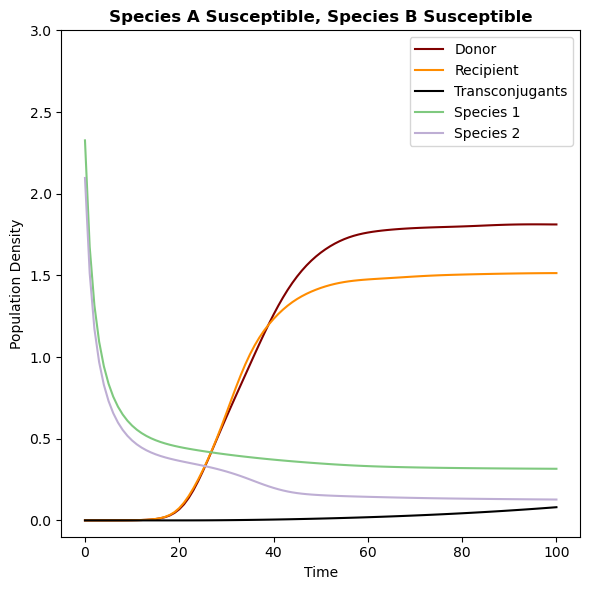

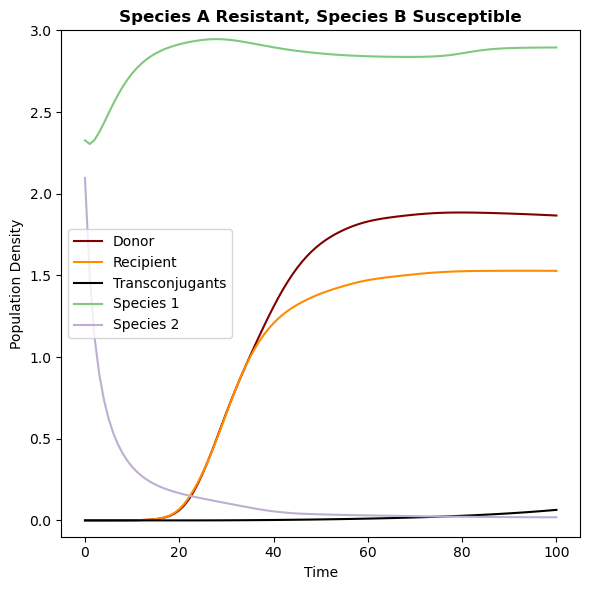

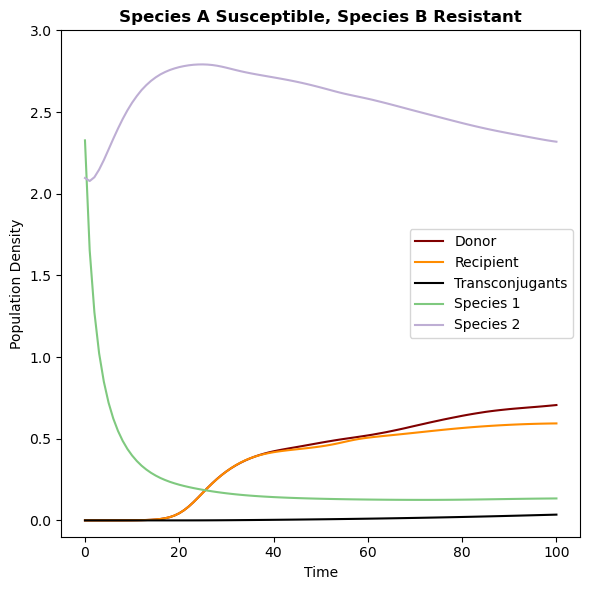

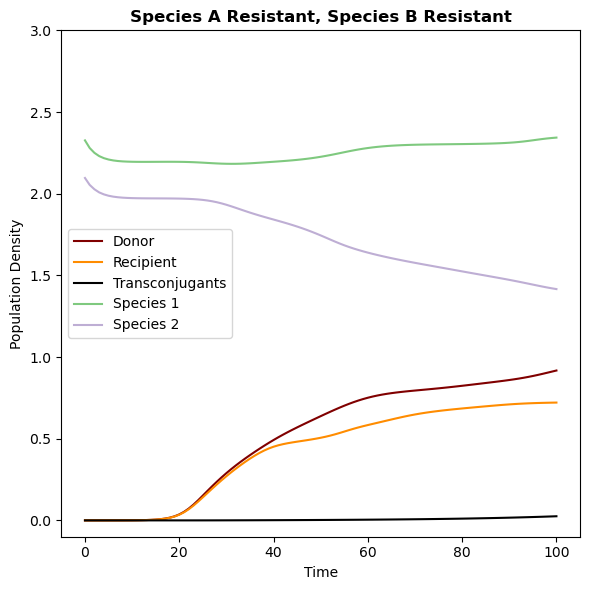

In [20]:
species2_model.plot_results(np.arange(0,101), species2_model_trans[0].mean(axis=0).T,
                            title='Species A Susceptible, Species B Susceptible',
                            drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                            figsize=(6,6), ylim=[-0.1, 3], save_fig=True, filename=f'{figdir}/exp_AaBa')
species2_model.plot_results(np.arange(0,101), species2_model_trans[1].mean(axis=0).T,
                            title='Species A Resistant, Species B Susceptible',
                            drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                            figsize=(6,6), ylim=[-0.1, 3], save_fig=True, filename=f'{figdir}/exp_AbBa')
species2_model.plot_results(np.arange(0,101), species2_model_trans[2].mean(axis=0).T,
                            title='Species A Susceptible, Species B Resistant',
                            drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                            figsize=(6,6), ylim=[-0.1, 3], save_fig=True, filename=f'{figdir}/exp_AaBb')
species2_model.plot_results(np.arange(0,101), species2_model_trans[3].mean(axis=0).T,
                            title='Species A Resistant, Species B Resistant',
                            drt_colours=['maroon', 'darkorange', 'black'], cmap='Accent',
                            figsize=(6,6), ylim=[-0.1, 3], save_fig=True, filename=f'{figdir}/exp_AbBb')

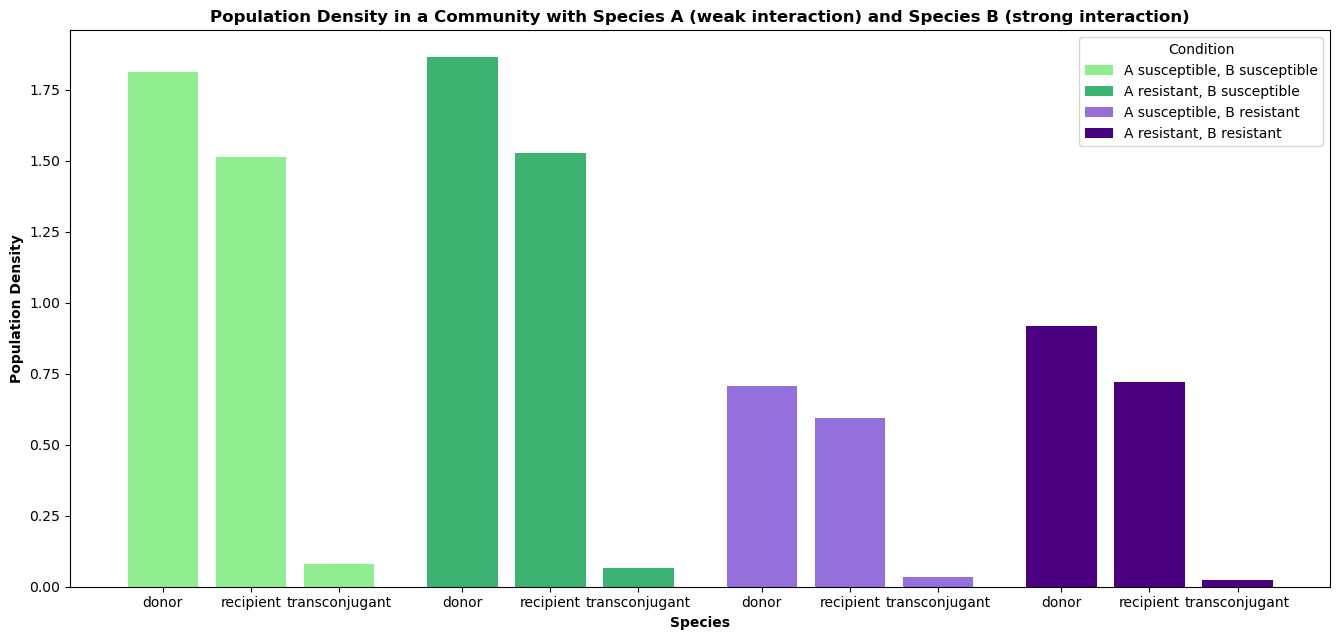

In [40]:
# --- PLOT SPECIES DENSITIES WHEN ALTERNATING COMMUNITY COMPOSTION ---
fig, ax = plt.subplots(figsize=(13.5,6.5))
plt.bar(x=[0.25,0.5,0.75], height=species2_model_trans[0].mean(axis=0)[:3,-1], width=0.2, label='A susceptible, B susceptible', color='lightgreen')
plt.bar(x=[1.1,1.35,1.6], height=species2_model_trans[1].mean(axis=0)[:3,-1], width=0.2, label='A resistant, B susceptible', color='mediumseagreen')
plt.bar(x=[1.95,2.2,2.45], height=species2_model_trans[2].mean(axis=0)[:3,-1], width=0.2, label='A susceptible, B resistant', color='mediumpurple')
plt.bar(x=[2.8,3.05,3.3], height=species2_model_trans[3].mean(axis=0)[:3,-1], width=0.2, label='A resistant, B resistant', color='indigo')
plt.title('Population Density in a Community with Species A (weak interaction) and Species B (strong interaction)', fontweight='bold')
plt.xlabel('Species', fontweight='bold')
plt.xticks([0.25,0.5,0.75, 1.1,1.35,1.6, 1.95,2.2,2.45, 2.8,3.05,3.3], labels=['donor','recipient','transconjugant', 'donor','recipient','transconjugant', 'donor','recipient','transconjugant', 'donor','recipient','transconjugant'])
plt.ylabel('Population Density', fontweight='bold')
#plt.ylim(0,1.6)
plt.legend(title='Condition')
plt.tight_layout()
plt.savefig(f'{figdir}/exp_speciesAB.png', dpi=500)
plt.show()